<style>
@media print {
    /* Prevent page breaks inside cells and outputs */
    .jp-Cell, .cell, div.output, div.input {
        page-break-inside: avoid !important;
        break-inside: avoid !important;
    }
    /* Remove extra margins and padding during printing */
    body {
        margin: 0 !important;
        padding: 0 !important;
    }
}
</style>

# 1. Decision Trees as Interpretable Models
## (a) Download and Uploading With tkinter

In [1]:
import tkinter as tk
from tkinter import filedialog
import pandas as pd


def load_acute_inflammations_data():
  root = tk.Tk()
  root.withdraw()
  root.attributes('-topmost', True)

  file_path = filedialog.askopenfilename(
      title='Select Data File',
      filetypes=[('Data Files', '*.data;*.txt;*.csv'), ('All Files', '*.*')],
  )
  if not file_path:
    return None

  column_names = [
      'Temperature',
      'Nausea',
      'Lumbar_Pain',
      'Urine_Pushing',
      'Micturition_Pains',
      'Burning_Urethra',
      'Decision_Inflammation_Bladder',
      'Decision_Nephritis',
  ]

  df = None
  for enc in ['utf-16', 'utf-8', 'latin1', 'cp1252']:
    try:
      df = pd.read_csv(
          file_path,
          sep=r'\s+|\t+',
          decimal=',',
          names=column_names,
          engine='python',
          encoding=enc,
      )
      break
    except UnicodeDecodeError:
      continue

  if df is None:
    raise ValueError('Failed to load file with common encodings.')

  for col in df.columns:
    if col != 'Temperature' and df[col].dtype == object:
      df[col] = df[col].map({'yes': 1, 'no': 0})

  print(f'Data shape: {df.shape}')
  return df


# Execute and display
df = load_acute_inflammations_data()
if df is not None:
  display(df.head())

Data shape: (120, 8)


,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Decision_Inflammation_Bladder,Decision_Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


Independent variables include patient temperature, nausea, lumbar pain, urine pushing, micturition pains, and burning of urethra  and Dependent variables (decisions) include inflammation of urinary bladder and nephritis of renal pelvis origin.   

## (b) Build a decision tree on the whole data set and plot it
#### Label Powerset Method
I applied the Label Powerset method to combine the two dependent variables into a single multi-class target variable.This approach was used to enable the decision tree model to capture the simultaneous conditions and correlations between both diseases. The combined class states are mapped as 0_0 (neither), 1_0 (bladder inflammation only), 0_1 (nephritis only), and 1_1 (both diseases).

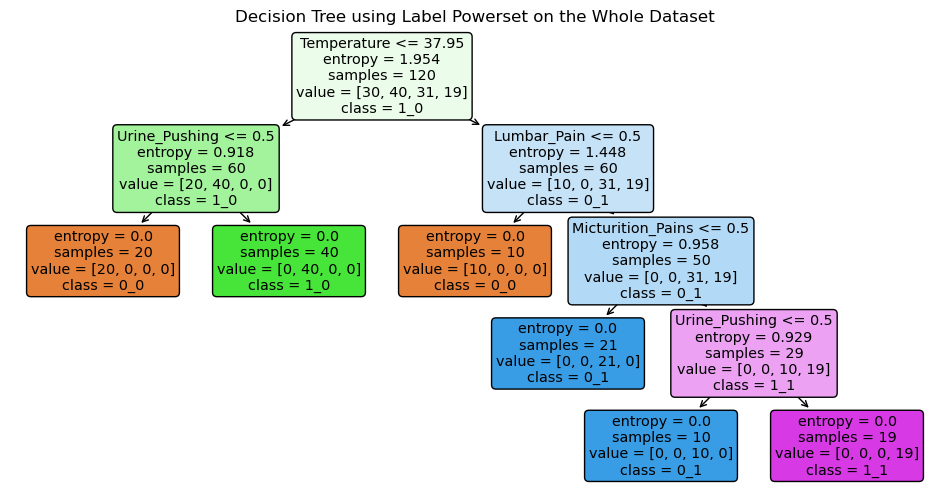

In [2]:
import pandas as pd
from sklearn import tree
import matplotlib.pyplot as plt

# 1. Define independent variables (features)
feature_names = [
    'Temperature',
    'Nausea',
    'Lumbar_Pain',
    'Urine_Pushing',
    'Micturition_Pains',
    'Burning_Urethra'
]
X = df[feature_names]

# 2. Implement the Label Powerset method to combine the two target variables into a single multi-class target variable
y_combined = df['Decision_Inflammation_Bladder'].astype(str) + "_" + df['Decision_Nephritis'].astype(str)
y, class_names = pd.factorize(y_combined)

# 3. Build a decision tree classifier on the whole dataset using entropy as the criterion
dt = tree.DecisionTreeClassifier(criterion='entropy')
dt.fit(X, y)

# 4. Plot and display the decision tree
plt.figure(figsize=(12, 6))
tree.plot_tree(
    dt,
    feature_names=feature_names,
    class_names=[str(cls) for cls in class_names],
    filled=True,
    rounded=True
)
plt.title("Decision Tree using Label Powerset on the Whole Dataset")
plt.show()

# 5. Optional: Export the decision tree structure to a Graphviz dot file for rule extraction
dotfile = open("dt_acute.dot", 'w')
tree.export_graphviz(
    dt,
    out_file=dotfile,
    feature_names=feature_names,
    class_names=[str(cls) for cls in class_names],
    filled=True
)
dotfile.close()

## (c) Convert the decision rules into a set of IF-THEN rules.

Rule 1:IF Temperature $\le$ 37.95 AND Urine_Pushing $\le$ 0.5,THEN Class = 0_0 (No bladder inflammation, No nephritis)./.....Rule 2:IF Temperature $\le$ 37.95 AND Urine_Pushing > 0.5,THEN Class = 1_0 (Bladder inflammation only)./..... Rule 3:IF Temperature > 37.95 AND Lumbar_Pain $\le$ 0.5,THEN Class = 0_0 (No bladder inflammation, No nephritis)./.......... Rule 4:IF Temperature > 37.95 AND Lumbar_Pain > 0.5 AND Micturition_Pains $\le$ 0.5,THEN Class = 0_1 (Nephritis only)./ .....Rule 5:IF Temperature > 37.95 AND Lumbar_Pain > 0.5 AND Micturition_Pains > 0.5 AND Urine_Pushing $\le$ 0.5,THEN Class = 0_1 (Nephritis only)./ ........Rule 6:IF Temperature > 37.95 AND Lumbar_Pain > 0.5 AND Micturition_Pains > 0.5 AND Urine_Pushing > 0.5,THEN Class = 1_1 (Both bladder inflammation and nephritis).

## (d) Use cost-complexity pruning to find a minimal decision tree?
Alpha Path Extraction: Extracted the pruning path and effective alpha ($\alpha$) values from the initial unpruned decision tree.// Cross-Validation: Executed 5-fold cross-validation ($\text{K-Fold} = 5$) for each alpha value to compute the mean validation error.//Optimal Selection & Pruning: Selected the optimal alpha yielding the minimum error and constructed the final pruned decision tree.//Since the optimal alpha value resulted in zero ($\alpha = 0.0000$), the decision tree structure remains completely unchanged and identical to the previous state. This indicates that the dataset is fully separable and noise-free, meaning the tree did not require any pruning or branch removal to achieve optimal accuracy.

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

# 1. Compute the pruning path and effective alpha values from the base decision tree
clf_base = DecisionTreeClassifier(criterion='entropy', random_state=42)
clf_base.fit(X, y)
path = clf_base.cost_complexity_pruning_path(X, y)
ccp_alphas = path.ccp_alphas

# 2. Set up 5-fold cross-validation (K-Fold = 5)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
alpha_results = []

for alpha in ccp_alphas:
  # Build decision tree classifier with the current alpha value
  dt_pruned = DecisionTreeClassifier(
      criterion='entropy', ccp_alpha=alpha, random_state=42
  )

  # Calculate cross-validation accuracy scores across 5 folds and convert to mean error
  scores = cross_val_score(dt_pruned, X, y, cv=kfold, scoring='accuracy')
  mean_error = 1.0 - np.mean(scores)

  # Fit on the full dataset to check the number of leaves (model complexity)
  dt_pruned.fit(X, y)
  n_leaves = dt_pruned.get_n_leaves()

  alpha_results.append(
      {'alpha': alpha, 'mean_error': mean_error, 'n_leaves': n_leaves}
  )

# 3. Convert results into a DataFrame to inspect different alpha values
df_results = pd.DataFrame(alpha_results)
print('Evaluation results for different alpha values:')
print(df_results.head(10))

# 4. Find the optimal alpha value (minimum mean error)
optimal_row = df_results.loc[df_results['mean_error'].idxmin()]
optimal_alpha = optimal_row['alpha']

print(f'\nOptimal Alpha: {optimal_alpha}')
print(f'Minimum Mean Error: {optimal_row["mean_error"]:.4f}')

# 5. Train the final pruned decision tree using the optimal alpha (without plotting)
final_pruned_tree = DecisionTreeClassifier(
    criterion='entropy', ccp_alpha=optimal_alpha, random_state=42
)
final_pruned_tree.fit(X, y)
print(
    f'Final pruned decision tree successfully trained with optimal alpha:'
    f' {optimal_alpha:.4f}'
)

Evaluation results for different alpha values:
      alpha  mean_error  n_leaves
0  0.000000    0.000000         6
1  0.199592    0.108333         4
2  0.325011    0.216667         3
3  0.459148    0.341667         2
4  0.770426    0.558333         1

Optimal Alpha: 0.0
Minimum Mean Error: 0.0000
Final pruned decision tree successfully trained with optimal alpha: 0.0000


# 2. The LASSO and Boosting for Regression

## (a) Download and Upload wtih tkinter and set training and test data
Variables Description : Independent variables ($X$): Socioeconomic, demographic, and law enforcement features (columns 0 to 126) and Dependent variable ($y$): ViolentCrimesPerPop (total per capita violent crimes, column 127).

In [4]:
import pandas as pd
import tkinter as tk
from tkinter import filedialog

root = tk.Tk()
root.withdraw()

file_path = filedialog.askopenfilename(
    title="Select Communities and Crime Data File",
    filetypes=[("Data Files", "*.data"), ("All Files", "*.*")],
)

if file_path:
  df = pd.read_csv(file_path, header=None, na_values=["?"])
  display(df.head())

  X, y = df.iloc[:, :-1], df.iloc[:, -1]
  X_train, y_train = X.iloc[:1495], y.iloc[:1495]
  X_test, y_test = X.iloc[1495:], y.iloc[1495:]

  print("Train/Test shapes:", X_train.shape, X_test.shape)
else:
  print("No file selected.")

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


Train/Test shapes: (1495, 127) (499, 127)


## (b)  Data imputation technique
Identifying non-predictive features :  On the UCI website and dataset files, there is a text file named communities.names detailing all column names and descriptions.Non-predictive features (such as city name, state, county, and community ID) are specified there./// First, I checked which features contained missing values, as shown in the output. Then, considering the nature and scale of these features, among the available imputation strategies such as 'Median Baseline' and 'KNN Imputer', I chose the 'Iterative Imputer (MICE)' method./// I also need to apply a scaling block (such as StandardScaler or RobustScaler) within the pipeline before imputation to prevent differing feature scales from negatively affecting distance calculations or internal regression models."

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline

# ----------------------------------------

# Assuming 'df' is already loaded in your environment
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Exclude the first 5 non-predictive columns (indices 0 to 4)
X_features = X.iloc[:, 5:]

# Check and count missing values for each feature excluding the first 5 columns
missing_values = X_features.isnull().sum()
missing_values_filtered = missing_values[missing_values > 0]

print("Missing values count per feature (excluding the first 5 columns):")
print(missing_values_filtered)
print(f"\nTotal features checked: {X_features.shape[1]}")
print(f"Features with missing values: {len(missing_values_filtered)}")

print("-" * 50)

# Split data: First 1495 rows as training set, the rest as test set (preventing data leakage)
X_train = X_features.iloc[:1495]
X_test = X_features.iloc[1495:]
y_train = y.iloc[:1495]
y_test = y.iloc[1495:]

# Constructing the Pipeline with StandardScaler and MICE (IterativeImputer)
# Fitting is done strictly on training data to prevent information leakage
pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('imputer', IterativeImputer(random_state=42, max_iter=10))
])

# Apply pipeline separately to training and test data
X_train_processed = pipeline.fit_transform(X_train)
X_test_processed = pipeline.transform(X_test)

print("Pipeline successfully applied: Scaling and MICE imputation performed separately on train and test sets.")

Missing values count per feature (excluding the first 5 columns):
30        1
101    1675
102    1675
103    1675
104    1675
105    1675
106    1675
107    1675
108    1675
109    1675
110    1675
111    1675
112    1675
113    1675
114    1675
115    1675
116    1675
117    1675
121    1675
122    1675
123    1675
124    1675
126    1675
dtype: int64

Total features checked: 122
Features with missing values: 23
--------------------------------------------------
Pipeline successfully applied: Scaling and MICE imputation performed separately on train and test sets.


C:\Users\Dr.yazdani\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:796: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


## (c)  Plot a correlation matrix for the features in the data set
Due to the large number of features, I used a clustermap, and this correlation analysis was performed exclusively on the training data to prevent data leakage.

C:\Users\Dr.yazdani\anaconda3\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
C:\Users\Dr.yazdani\anaconda3\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


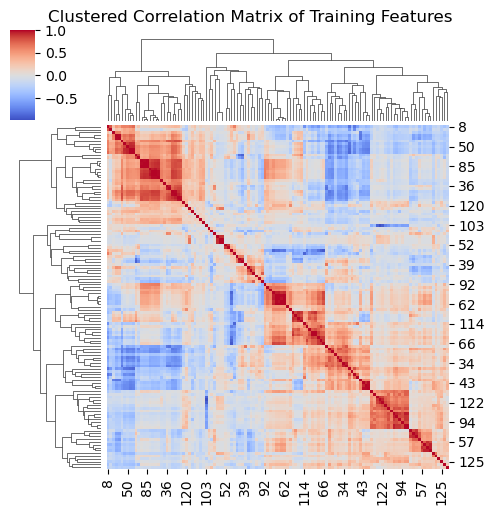

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Convert the processed training data back to a DataFrame to preserve column names
# (Computed strictly on training data to prevent data leakage)
X_train_df = pd.DataFrame(X_train_processed, columns=X_train.columns)

# Calculate the Pearson correlation matrix
corr_matrix = X_train_df.corr()

# Plot a clustered heatmap with optimized size to save space in the report
clustered_plot = sns.clustermap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0,
    figsize=(5,5),  # Reduced from (12, 12) to save report pages
    col_cluster=True,
    row_cluster=True,
)

# Adjust title position for the smaller figure size
clustered_plot.fig.suptitle(
    'Clustered Correlation Matrix of Training Features', y=1.02, fontsize=12
)
plt.show()

## (d) Calculate the Coefficient of Variation CV for each feature

In [7]:
import pandas as pd

# Calculate sample mean (m) and sample standard deviation (s) for each feature in the training set
train_mean = X_train.mean()
train_std = X_train.std(ddof=1)

# Calculate the Coefficient of Variation (CV)
coefficient_of_variation = train_std / train_mean

# Create a DataFrame for an organized presentation of the results
cv_df = pd.DataFrame({
    'Mean (m)': train_mean,
    'Std Dev (s)': train_std,
    'Coefficient of Variation (CV)': coefficient_of_variation
})

print("Coefficient of Variation (CV) for each feature in training set:")
print(cv_df)

Coefficient of Variation (CV) for each feature in training set:
     Mean (m)  Std Dev (s)  Coefficient of Variation (CV)
5    0.058167     0.130359                       2.241105
6    0.461732     0.164284                       0.355800
7    0.179839     0.256970                       1.428885
8    0.752829     0.248594                       0.330213
9    0.153712     0.208910                       1.359100
..        ...          ...                            ...
122  0.080502     0.149957                       1.862773
123  0.713054     0.206771                       0.289979
124  0.451883     0.410967                       0.909454
125  0.093304     0.238201                       2.552946
126  0.190753     0.155815                       0.816843

[122 rows x 3 columns]


## (e) Pick √128 features with highest CV, and make scatter plots and box plots for
These top 11 features with the highest Coefficient of Variation (CV) are primarily absolute count and socio-demographic variables (such as total population, poverty counts, homeless counts, immigrant counts, and specific law enforcement metrics). Due to their highly skewed distributions across different communities, they exhibit high relative dispersion.

Coefficient of Variation (CV) for each feature in training set:
   Mean (m)  Std Dev (s)  Coefficient of Variation (CV)
5  0.058167     0.130359                       2.241105
6  0.461732     0.164284                       0.355800
7  0.179839     0.256970                       1.428885
8  0.752829     0.248594                       0.330213
9  0.153712     0.208910                       1.359100

Top 11 features with the highest CV:
Index([95, 94, 54, 56, 125, 32, 5, 101, 15, 113, 76], dtype='int64')


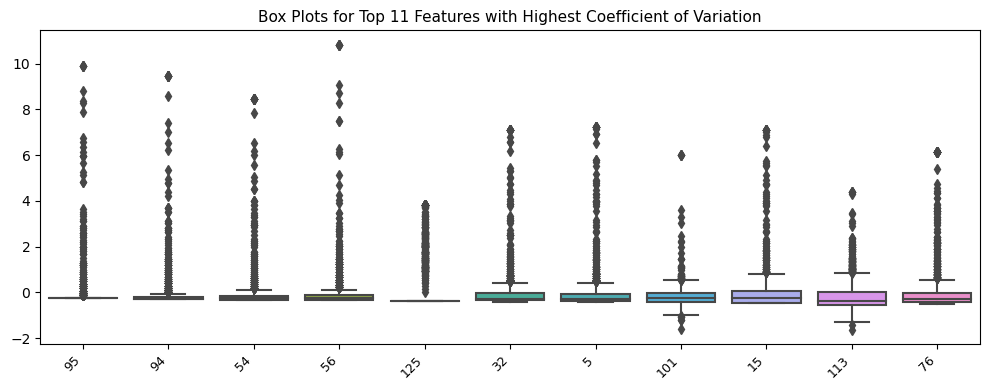

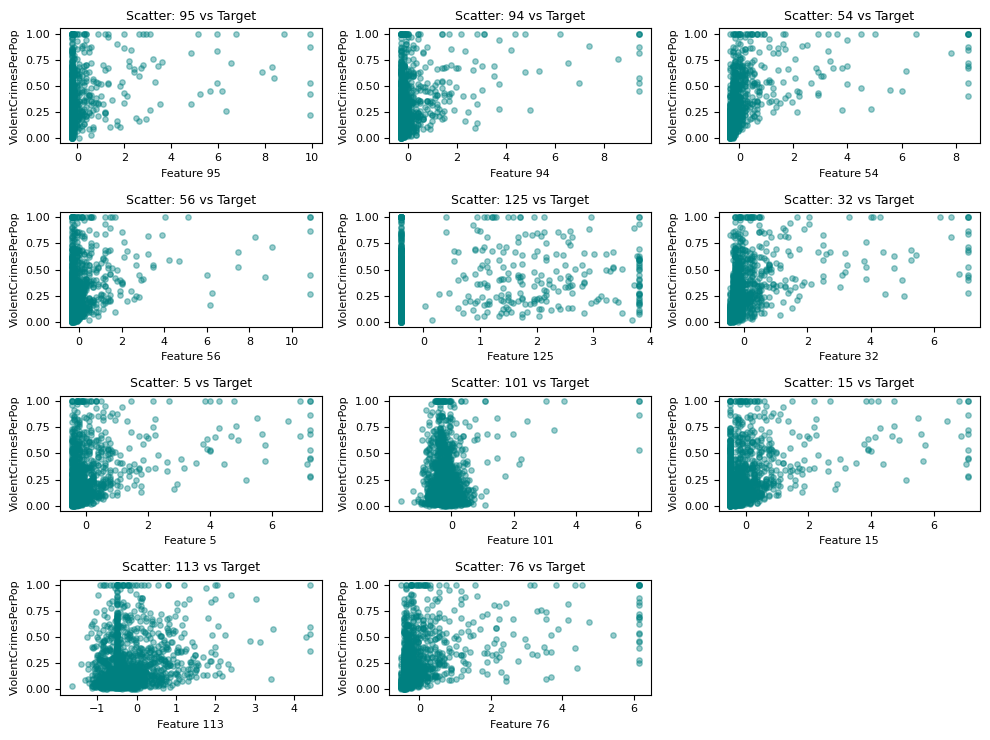

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Calculate CV on the ORIGINAL unscaled training data (X_train)
train_mean = X_train.mean()
train_std = X_train.std(ddof=1)

# Calculate the Coefficient of Variation (CV)
coefficient_of_variation = train_std / train_mean

# Create a DataFrame for an organized presentation of the results
cv_df = pd.DataFrame({
    'Mean (m)': train_mean,
    'Std Dev (s)': train_std,
    'Coefficient of Variation (CV)': coefficient_of_variation,
})

print('Coefficient of Variation (CV) for each feature in training set:')
print(cv_df.head())  # Display head to save space in report

# Select top sqrt(128) = 11 features with the highest Coefficient of Variation
top_11_features = (
    cv_df.sort_values(by='Coefficient of Variation (CV)', ascending=False)
    .head(11)
    .index
)
print('\nTop 11 features with the highest CV:')
print(top_11_features)

# 2. Convert processed training data to DataFrame for plotting
X_train_df = pd.DataFrame(X_train_processed, columns=X_features.columns)

# Box plots for the top 11 features (Optimized size for compactness)
plt.figure(figsize=(10, 4))
sns.boxplot(data=X_train_df[top_11_features])
plt.title(
    'Box Plots for Top 11 Features with Highest Coefficient of Variation',
    fontsize=11,
)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

# Scatter plots of top 11 features against the target variable (y_train) - Compact grid
fig, axes = plt.subplots(4, 3, figsize=(10, 7.5))
axes = axes.flatten()

for i, feature in enumerate(top_11_features):
  axes[i].scatter(
      X_train_df[feature], y_train, alpha=0.4, color='teal', s=15
  )
  axes[i].set_title(f'Scatter: {feature} vs Target', fontsize=9)
  axes[i].set_xlabel(f'Feature {feature}', fontsize=8)
  axes[i].set_ylabel('ViolentCrimesPerPop', fontsize=8)
  axes[i].tick_params(labelsize=8)

# Hide any unused subplots in the grid
for j in range(len(top_11_features), len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## (f)  Fit a linear model using least squares to the training set and report the test error
I fitted a linear regression model on the dependent variable 'ViolentCrimesPerPop' using these 11 features.

In [9]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm

# Target variable name
target_column = 'ViolentCrimesPerPop'

# Convert processed test data to DataFrame for feature selection
X_test_df = pd.DataFrame(X_test_processed, columns=X_features.columns)

# Extract the top 11 features for both training and test sets
X_train_top11 = X_train_df[top_11_features]
X_test_top11 = X_test_df[top_11_features]

# Add a constant (intercept) for statsmodels OLS regression
X_train_sm = sm.add_constant(X_train_top11)
X_test_sm = sm.add_constant(X_test_top11)

# 1. Fit a linear model using Ordinary Least Squares (OLS) on the training set
ols_model = sm.OLS(y_train, X_train_sm).fit()

# Print regression coefficients, standard errors, t-values, and p-values (significance)
print('--- Regression Coefficients and Significance ---')
print(ols_model.summary().tables[1])

# 2. Predict on the test set
y_pred_test = ols_model.predict(X_test_sm)

# 3. Calculate and report the test error (MSE and RMSE)
test_mse = mean_squared_error(y_test, y_pred_test)
test_rmse = np.sqrt(test_mse)

print(f'\nTarget Variable: {target_column}')
print(f'Test Mean Squared Error (MSE): {test_mse:.4f}')
print(f'Test Root Mean Squared Error (RMSE): {test_rmse:.4f}')

--- Regression Coefficients and Significance ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2359      0.006     39.859      0.000       0.224       0.248
95             0.0251      0.007      3.351      0.001       0.010       0.040
94             0.0057      0.010      0.573      0.567      -0.014       0.025
54             0.1263      0.016      7.813      0.000       0.095       0.158
56             0.0102      0.009      1.177      0.239      -0.007       0.027
125            0.0308      0.006      5.162      0.000       0.019       0.043
32             0.1206      0.023      5.342      0.000       0.076       0.165
5             -0.2671      0.051     -5.268      0.000      -0.366      -0.168
101           -0.0950      0.014     -6.718      0.000      -0.123      -0.067
15             0.0228      0.046      0.496      0.620      -0.067       0.113
113

## (g) Fit a ridge regression model on the training set, with λ chosen by cross-validation.

In [10]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold

# 5-fold CV & Grid Search for Ridge Regression
kf = KFold(n_splits=5, shuffle=True, random_state=42)
ridge_cv = GridSearchCV(
    estimator=Ridge(),
    param_grid={'alpha': np.logspace(-4, 4, 200)},
    cv=kf,
    scoring='neg_mean_squared_error',
)

ridge_cv.fit(X_train_top11, y_train)
best_lambda = ridge_cv.best_params_['alpha']

# Predict and evaluate on test set
y_pred_ridge = ridge_cv.best_estimator_.predict(X_test_top11)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)

print(
    f'Ridge -> Best Alpha: {best_lambda:.4f} | MSE: {mse_ridge:.4f} | RMSE:'
    f' {rmse_ridge:.4f}'
)

Ridge -> Best Alpha: 18.4642 | MSE: 0.0292 | RMSE: 0.1710


## (h)  Fit a LASSO model on the training set, with λ chosen by cross-validation

In [11]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler

# Handle dataframes & extract top 11 features
X_train_df = pd.DataFrame(
    X_train_processed
    if 'X_train_processed' in globals()
    else X_train.fillna(0),
    columns=X_features.columns,
)
X_test_df = pd.DataFrame(
    X_test_processed if 'X_test_processed' in globals() else X_test.fillna(0),
    columns=X_features.columns,
)
X_tr, X_te = X_train_df[top_11_features], X_test_df[top_11_features]

kf = KFold(n_splits=5, shuffle=True, random_state=42)
grid = {'alpha': np.logspace(-4, 4, 200)}


# Function to train and evaluate Lasso
def run_lasso(X_tr_data, X_te_data):
  cv = GridSearchCV(
      Lasso(max_iter=10000, random_state=42),
      grid,
      cv=kf,
      scoring='neg_mean_squared_error',
  ).fit(X_tr_data, y_train)
  pred = cv.best_estimator_.predict(X_te_data)
  return (
      cv.best_params_['alpha'],
      mean_squared_error(y_test, pred),
      np.sqrt(mean_squared_error(y_test, pred)),
      top_11_features[cv.best_estimator_.coef_ != 0],
  )


# Run for both conditions
a_un, mse_un, rmse_un, vars_un = run_lasso(X_tr, X_te)
X_tr_s, X_te_s = StandardScaler().fit_transform(X_tr), StandardScaler().fit_transform(X_te)
a_st, mse_st, rmse_st, vars_st = run_lasso(X_tr_s, X_te_s)

# Compact Comparison Report
comp_df = pd.DataFrame({
    'Condition': ['Unstandardized', 'Standardized'],
    'Best Alpha': [a_un, a_st],
    'Test MSE': [mse_un, mse_st],
    'Test RMSE': [rmse_un, rmse_st],
    'Selected Vars': [len(vars_un), len(vars_st)],
})
print(comp_df.to_string(index=False))

     Condition  Best Alpha  Test MSE  Test RMSE  Selected Vars
Unstandardized    0.001763  0.029203   0.170888              9
  Standardized    0.001763  0.029766   0.172528             10


## (i)  Fit a PCR model on the training set
Since the number of components ranges from 1 to 11, I need to evaluate 1 to 11 principal components using 5-fold cross-validation// I will use a Pipeline combining StandardScaler, PCA, and LinearRegression integrated with GridSearchCV to automatically evaluate 1 to 11 components across 5 folds.// Based on the results of the 5-fold cross-validation, the algorithm has selected 11 as the optimal number of principal components ($M$).

In [12]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Handle dataframes & extract top 11 features
X_train_df = pd.DataFrame(
    X_train_processed
    if 'X_train_processed' in globals()
    else X_train.fillna(0),
    columns=X_features.columns,
)
X_test_df = pd.DataFrame(
    X_test_processed if 'X_test_processed' in globals() else X_test.fillna(0),
    columns=X_features.columns,
)
X_tr, X_te = X_train_df[top_11_features], X_test_df[top_11_features]

# PCR Pipeline and Grid Search (1 to 11 components)
pcr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('linear_regression', LinearRegression()),
])
kf = KFold(n_splits=5, shuffle=True, random_state=42)

pcr_cv = GridSearchCV(
    pcr_pipeline,
    {'pca__n_components': range(1, 12)},
    cv=kf,
    scoring='neg_mean_squared_error',
).fit(X_tr, y_train)

best_m = pcr_cv.best_params_['pca__n_components']
y_pred_pcr = pcr_cv.best_estimator_.predict(X_te)
mse_pcr = mean_squared_error(y_test, y_pred_pcr)
rmse_pcr = np.sqrt(mse_pcr)

print(
    f'PCR -> Best M: {best_m} | Test MSE: {mse_pcr:.4f} | Test RMSE:'
    f' {rmse_pcr:.4f}'
)

PCR -> Best M: 11 | Test MSE: 0.0297 | Test RMSE: 0.1722


# (j)  to fit a boosting tree to the data
In boosting algorithms, models are executed sequentially; the process begins with weak learners, and at each step, subsequent models are employed to reduce the residuals and correct the shortcomings of the previous model, thereby progressively improving prediction accuracy.// I will start the process with shallow regression trees as base learners to prevent overfitting. Then, by applying an $L_1$ penalty (via the reg_alpha parameter in XGBoost), I will control dimensionality and select key features by zeroing out the coefficients of non-influential variables.// The next step is to optimize the $\alpha$ value using cross-validation.

In [13]:
!pip install xgboost

In [14]:
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold

# Handle dataframes & extract top 11 features
X_train_df = pd.DataFrame(
    X_train_processed
    if 'X_train_processed' in globals()
    else X_train.fillna(0),
    columns=X_features.columns,
)
X_test_df = pd.DataFrame(
    X_test_processed if 'X_test_processed' in globals() else X_test.fillna(0),
    columns=X_features.columns,
)
X_tr, X_te = X_train_df[top_11_features], X_test_df[top_11_features]

# XGBoost with L1 Regularization (reg_alpha) & 5-fold CV
kf = KFold(n_splits=5, shuffle=True, random_state=42)
xgb_cv = GridSearchCV(
    xgb.XGBRegressor(max_depth=3, learning_rate=0.1, n_estimators=100, random_state=42),
    {'reg_alpha': [0.0, 0.001, 0.01, 0.1, 1.0, 10.0, 50.0]},
    cv=kf,
    scoring='neg_mean_squared_error',
).fit(X_tr, y_train)

best_alpha = xgb_cv.best_params_['reg_alpha']
y_pred_xgb = xgb_cv.best_estimator_.predict(X_te)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)

print(
    f'XGBoost -> Best Alpha: {best_alpha} | Test MSE: {mse_xgb:.4f} | Test RMSE:'
    f' {rmse_xgb:.4f}'
)

XGBoost -> Best Alpha: 0.01 | Test MSE: 0.0193 | Test RMSE: 0.1391
